# Full interaction (Heisenberg + RKKY)

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables

using LinearAlgebra: norm
using Random: MersenneTwister
using Statistics: mean, std
using HDF5
using CSV
using DataFrames

using PyPlot; const plt = PyPlot;

## Analyse data

In [9]:
collect_from_h5(ar, name) = [ar["/T$(T)/$(name)"][] for T in ar["params/T_range"][]]

function make_observables_df(ar)
    params = read(ar, "params")
    L = params["L"][]
    T_range = collect(params["T_range"])
    β_range = 1.0 ./ T_range

    df = DataFrame("T" => T_range)
    
    # Energy
    E = collect_from_h5(ar, "E")
    insertcols!(df, "E_avg" => avg_energy.(E) / L^2, "E_var" => var_energy.(E) / L^2)
    # Specific heat
    insertcols!(df, "cV" => specific_heat.(E, β_range) / L^2)
    # Average chirality
    χ = collect_from_h5(ar, "chi")
    insertcols!(df, "chi_avg" => avg_chirality.(χ), "chi_var" => var_chirality.(χ))
    # Chirality susceptibility
    insertcols!(df, "susc_chi" => susc_chirality.(χ, L^2, β_range) / L^2)
    # Chirality Binder cumulant
    insertcols!(df, "binder_chi" => binder_chirality.(χ))
    # Chirality correlation length
    χ_at_q_min = collect_from_h5(ar, "chi_at_q_min")
    insertcols!(df, "corr_length_chi" => abs.(corr_length_chirality.(χ, χ_at_q_min, L)))
    # Average magnetization at K-point
    m_at_K = collect_from_h5(ar, "m_at_K")
    m_abs_at_K = [mapslices(norm, m, dims=(1,)) for m in m_at_K]
    insertcols!(df, "m_abs_at_K_avg" => mean.(m_abs_at_K), "m_abs_at_K_var" => std.(m_abs_at_K))
    # Magnetization at K-point: susceptibility
    insertcols!(df, "susc_spin_K" => susc_spin_K.(m_at_K, L^2, β_range) / L^2)
    # Magnetization at K-point: Binder cumulant
    insertcols!(df, "binder_spin_K" => binder_spin_K.(m_at_K))
    # Magnetization at K-point: Correlation length
    m_at_K_q_min = collect_from_h5(ar, "m_at_K_q_min")
    insertcols!(df, "corr_length_spin_K" => abs.(corr_length_spin_K.(m_at_K, m_at_K_q_min, L)))
    
    return df
end

make_observables_df (generic function with 1 method)

## Plot results

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


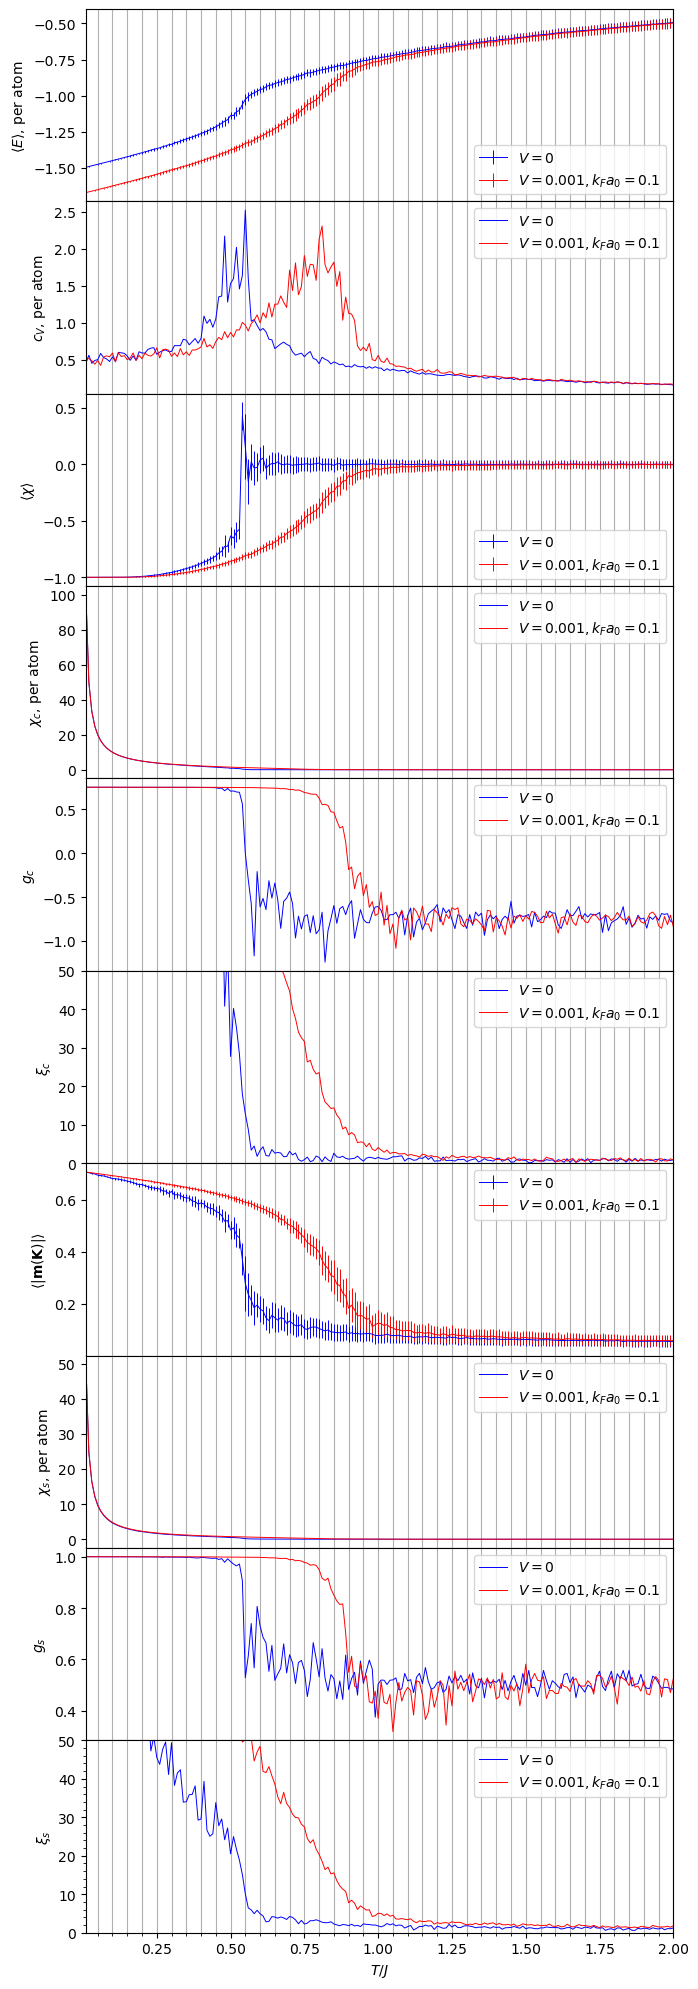

In [11]:
L = 24

fig = plt.figure(figsize=(7, 20))
let gs = plt.matplotlib.gridspec.GridSpec(10, 1, hspace=0), i = 1, ax = plt.subplot(gs[1])
    global add_plot_panel
    function add_plot_panel(;xticks=false)
        if i > 1
            ax = plt.subplot(gs[i], sharex=ax)
        end
        ax.grid(axis="x", which="both")
        if !xticks
            plt.setp(ax.get_xticklabels(), visible=false)
        end
        i += 1
        return ax
    end
end

df = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_L$(L).h5", "r"))
df0 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_no_rkky_L$(L).h5", "r"))

h5open("../../RKKY_temperature_scan/RKKY_T_scan_L$(L).h5", "r") do ar
    params = read(ar, "params")   
    V = params["Vpar"]
    lambda = params["lambda"]
    global rkky_label = "\$V=$(V), k_F a_0 = $(lambda)\$"
end

# Energy
ax = add_plot_panel()
ax.errorbar(df0.T, df0.E_avg, yerr=df0.E_var, lw=0.7, color="blue", label=raw"$V=0$")
ax.errorbar(df.T, df.E_avg, yerr=df.E_var, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\langle E\rangle$, per atom")
ax.legend(loc="lower right")

# Specific heat
ax = add_plot_panel()
ax.plot(df0.T, df0.cV, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(df.T, df.cV, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$c_V$, per atom")
ax.legend(loc="upper right")

# Average chirality
ax = add_plot_panel()
ax.errorbar(df0.T, df0.chi_avg, yerr=df0.chi_var, lw=0.7, color="blue", label=raw"$V=0$")
ax.errorbar(df.T, df.chi_avg, yerr=df.chi_var, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\langle\chi\rangle$")
ax.legend(loc="lower right")

# Chirality susceptibility
ax = add_plot_panel()
ax.plot(df0.T, df0.susc_chi, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(df.T, df.susc_chi, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\chi_c$, per atom")
ax.legend(loc="upper right")

# Chirality Binder cumulant
ax = add_plot_panel()
ax.plot(df0.T, df0.binder_chi, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(df.T, df.binder_chi, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$g_c$")
ax.legend(loc="upper right")

# Chirality correlation length
ax = add_plot_panel()
ax.plot(df0.T, df0.corr_length_chi, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(df.T, df.corr_length_chi, lw=0.7, color="red", label=rkky_label)
ax.set_ylim((0.0, 50.0))
ax.set_ylabel(raw"$\xi_c$")
ax.legend(loc="upper right")

# Average magnetization at K-point
ax = add_plot_panel()
ax.errorbar(df0.T, df0.m_abs_at_K_avg, yerr=df0.m_abs_at_K_var, lw=0.7, color="blue", label=raw"$V=0$")
ax.errorbar(df.T, df.m_abs_at_K_avg, yerr=df.m_abs_at_K_var, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\langle|\mathbf{m}(\mathbf{K})|\rangle$")
ax.legend(loc="upper right")

# Magnetization at K-point: susceptibility
ax = add_plot_panel()
ax.plot(df0.T, df0.susc_spin_K, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(df.T, df.susc_spin_K, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\chi_s$, per atom")
ax.legend(loc="upper right")

# Magnetization at K-point: Binder cumulant
ax = add_plot_panel()
ax.plot(df0.T, df0.binder_spin_K, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(df.T, df.binder_spin_K, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$g_s$")
ax.legend(loc="upper right")

# Magnetization at K-point: Correlation length
ax = add_plot_panel(xticks=true)
ax.plot(df0.T, df0.corr_length_spin_K, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(df.T, df.corr_length_spin_K, lw=0.7, color="red", label=rkky_label)
ax.set_ylim((0.0, 50.0))
ax.set_ylabel(raw"$\xi_s$")
ax.legend(loc="upper right")

# General plot setup
ax.set_xlim((first(df.T), last(df.T)))
ax.set_xlabel(raw"$T/J$")
ax.minorticks_on()
plt.tight_layout()
plt.show()
fig.savefig("rkky_temp_scan.pdf")

## Export results

In [18]:
CSV.write("RKKY_T_scan_V0.001_lambda0.1_L24.dat", df, delim="    ")
CSV.write("RKKY_T_scan_V0_L24.dat", df0, delim="    ")

"RKKY_T_scan_V0_L24.dat"